# 04 · Demand forecasting

**Question:** what will weekly demand be for the top categories over the next 12 weeks, and is a model better than simply repeating last year?

**Method** (code in `src/fdda/forecast/`):
* Weekly units for the top 8 H&M product groups (full weeks only).
* **Seasonal naive** baseline: the same week last year.
* **Prophet** with yearly seasonality, with and without a promo-intensity regressor (share of units sold ≥ 5% below the reference price). In the backtest the promo version is given the *realised* promo share for the test weeks, i.e. it assumes the promo calendar is planned ahead; the forward forecast uses last year's promo share as the plan.
* **Rolling-origin backtest:** 4 non-overlapping folds × 12-week horizon covering the last 48 weeks. MAPE (mean of |error| ÷ actual) and WAPE (Σ|error| ÷ Σ actual) by horizon bucket.

This notebook reads the tables written by `python -m fdda.forecast.backtest`.

In [1]:
import json

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from fdda import viz
from fdda.config import data_mode, load_settings, resolve_path

settings = load_settings()
MODE = data_mode(settings)
F = resolve_path(settings, "reports") / "forecast"
FIGURES = resolve_path(settings, "figures")
HIST = settings["forecast"]["chart_history_weeks"]
SCOPE = "all customers" if MODE == "full" else "10% customer sample"
NAMES = {
    "seasonal_naive": "Seasonal naive",
    "prophet": "Prophet",
    "prophet_promo": "Prophet + promo",
}


def load(name, dates=()):
    return pd.read_csv(F / f"{name}_{MODE}.csv", parse_dates=list(dates))


series = load("weekly_series", ["ds"])
preds = load("backtest_predictions", ["ds", "origin"])
metrics = load("backtest_metrics")
fc = load("forward_forecast", ["ds"])
cov = load("interval_coverage")
summary = json.loads((F / f"forecast_summary_{MODE}.json").read_text())
BEST = summary["best_prophet_model"]
CATS = summary["categories"]
viz.apply_style()
pd.options.display.float_format = "{:,.3f}".format
print(
    f"{MODE} data ({SCOPE}): {summary['weeks']} weeks, {summary['first_week']} to {summary['last_week']}; "
    f"test weeks {summary['test_weeks']}; best Prophet spec by WAPE: {NAMES[BEST]}"
)

full data (all customers): 104 weeks, 2018-09-24 to 2020-09-14; test weeks 2019-10-21 to 2020-09-14; best Prophet spec by WAPE: Prophet + promo


## 1. Backtest accuracy

Lower is better. A model is only useful if it beats the seasonal-naive baseline.

mape                                 wape                \
model              prophet prophet_promo seasonal_naive prophet prophet_promo   
category                                                                        
Accessories          0.209         0.265          0.248   0.194         0.229   
All categories       0.225         0.233          0.304   0.207         0.201   
Garment Full body    0.284         0.240          0.220   0.285         0.237   
Garment Lower body   0.157         0.148          0.250   0.172         0.153   
Garment Upper body   0.166         0.193          0.287   0.176         0.186   
Shoes                0.192         0.169          0.440   0.229         0.199   
Socks & Tights       0.309         0.292          0.314   0.272         0.253   
Swimwear             0.338         0.428          0.539   0.357         0.397   
Underwear            0.146         0.127          0.135   0.160         0.129   

                                   
model              seasonal_naive  
category                           
Accessories                 0.209  
All categories              0.252  
Garment Full body           0.216  
Garment Lower body          0.231  
Garment Upper body          0.276  
Shoes                       0.385  
Socks & Tights              0.237  
Swimwear                    0.367  
Underwear                   0.141

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


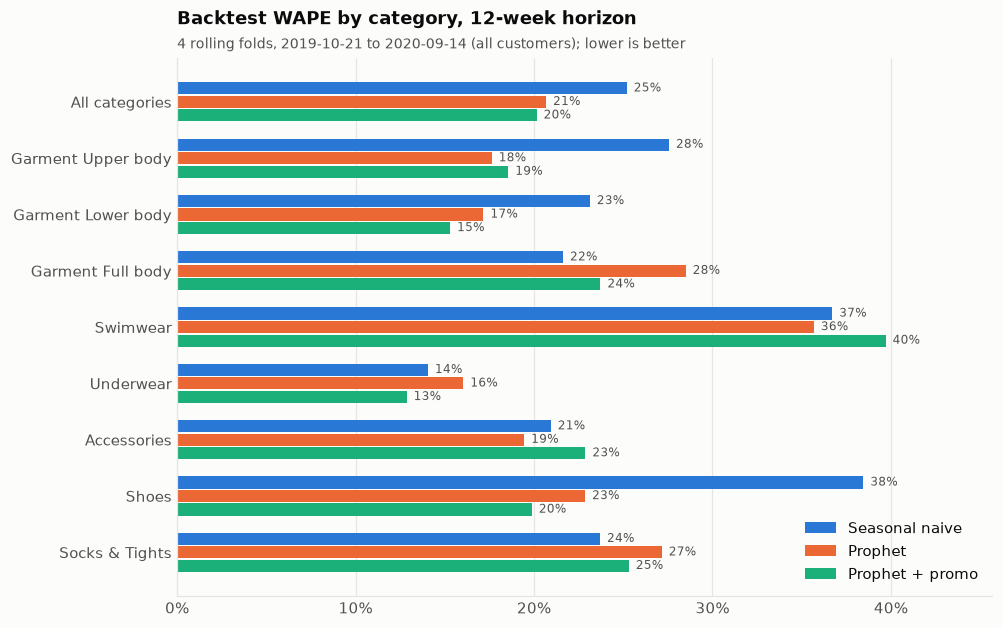

In [2]:
whole = summary["horizon_bucket_overall"]
m = metrics[metrics.bucket == whole]
tbl = m.pivot(index="category", columns="model", values=["mape", "wape"])
display(tbl)

wp = m.pivot(index="category", columns="model", values="wape").reindex(["All categories"] + CATS)
fig, ax = viz.new_fig(9, 5.6)
viz.hbar(
    ax, list(wp.index), {NAMES[k]: wp[k] for k in ["seasonal_naive", "prophet", "prophet_promo"]}
)
viz.pct_axis(ax, "x")
ax.legend(loc="lower right", ncols=1)
ax.set_title("Backtest WAPE by category, 12-week horizon", pad=22)
viz.subtitle(ax, f"4 rolling folds, {summary['test_weeks']} ({SCOPE}); lower is better")
viz.save_fig(fig, f"forecast_wape_by_category_{MODE}", FIGURES)
plt.show()

Accuracy by how far ahead the forecast is (all categories pooled).

model,mape_prophet,mape_prophet_promo,mape_seasonal_naive
bucket,,,
1-4,0.245,0.238,0.368
5-8,0.190,0.228,0.303
9-12,0.240,0.232,0.241
1-12,0.225,0.233,0.304


model,wape_prophet,wape_prophet_promo,wape_seasonal_naive
bucket,,,
1-4,0.220,0.179,0.316
5-8,0.196,0.216,0.272
9-12,0.205,0.208,0.175
1-12,0.207,0.201,0.252


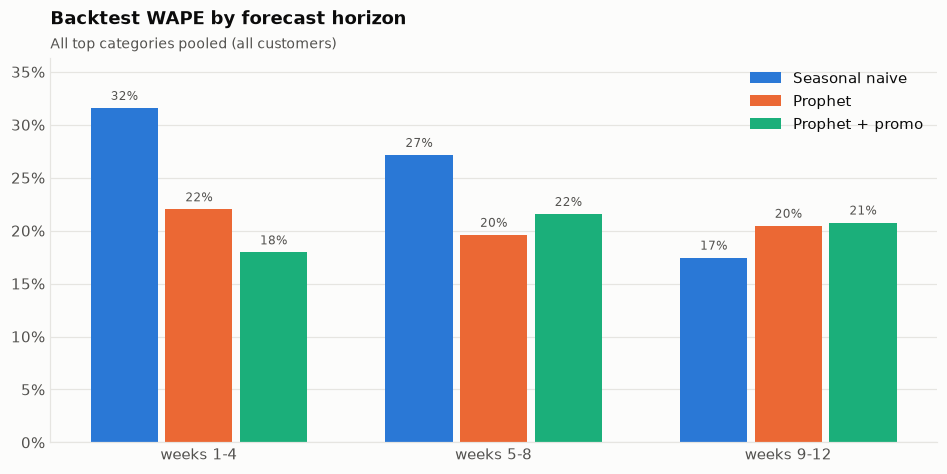

,model,share of actuals inside 80% interval
0,Prophet,0.737
1,Prophet + promo,0.602


In [3]:
a = metrics[metrics.category == "All categories"]
buckets = [b for b in a.bucket.unique() if b != whole]
for metric in ["mape", "wape"]:
    display(
        a.pivot(index="bucket", columns="model", values=metric)
        .reindex(buckets + [whole])
        .add_prefix(f"{metric}_")
    )

wb = a.pivot(index="bucket", columns="model", values="wape").reindex(buckets)
fig, ax = viz.new_fig(8.5, 4.2)
viz.vbar(
    ax,
    [f"weeks {b}" for b in buckets],
    {NAMES[k]: wb[k] for k in ["seasonal_naive", "prophet", "prophet_promo"]},
    label_fmt="{:.0%}",
)
viz.pct_axis(ax, "y")
ax.set_title("Backtest WAPE by forecast horizon", pad=22)
viz.subtitle(ax, f"All top categories pooled ({SCOPE})")
viz.save_fig(fig, f"forecast_wape_by_horizon_{MODE}", FIGURES)
plt.show()

display(
    cov.assign(model=cov.model.map(NAMES)).rename(
        columns={"coverage": "share of actuals inside 80% interval"}
    )
)

## 2. Backtest forecasts vs actuals

Each category's last 48 weeks: actual units, the best Prophet spec (with its 80% interval) and the seasonal-naive baseline, stitched across the 4 folds.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


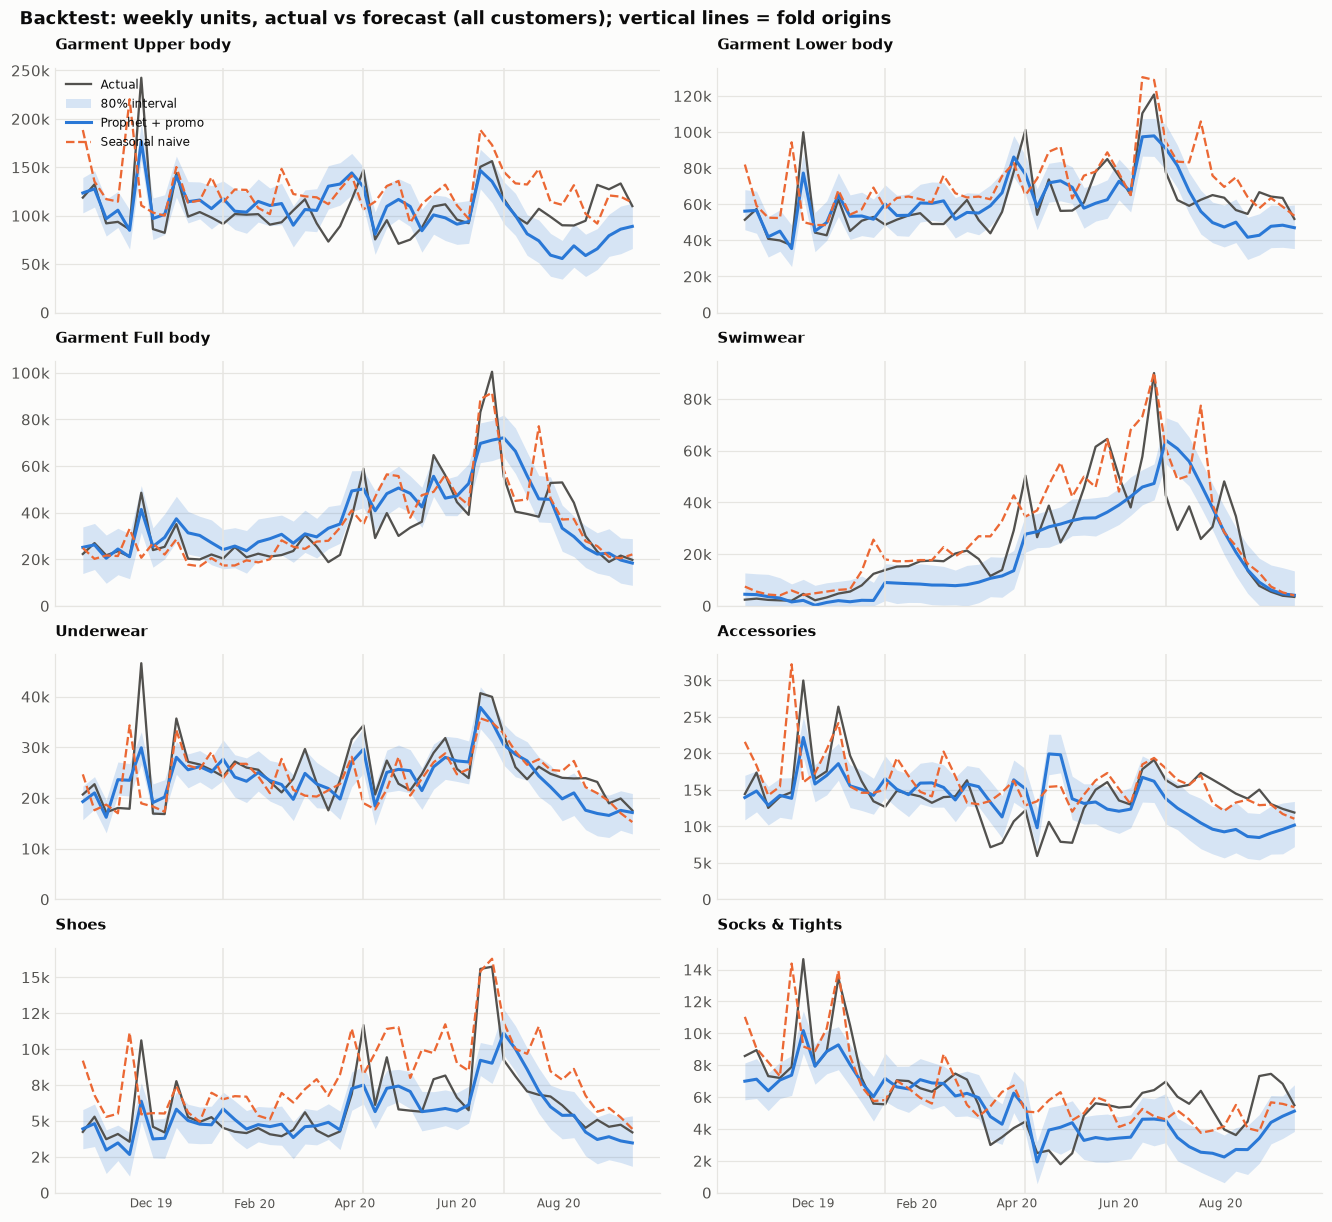

In [4]:
fig, axes = plt.subplots(4, 2, figsize=(12, 11), layout="constrained", sharex=True)
for ax, cat in zip(axes.flat, CATS, strict=True):
    pc = preds[preds.category == cat]
    b, nv = pc[pc.model == BEST], pc[pc.model == "seasonal_naive"]
    viz.forecast_panel(
        ax,
        (b.ds, b.y),
        (b.ds, b.yhat, b.yhat_lower, b.yhat_upper),
        baseline=(nv.ds, nv.yhat),
        title=cat,
        labels=("Actual", NAMES[BEST], "Seasonal naive"),
    )
    for o in pc.origin.unique()[1:]:
        ax.axvline(o, color=viz.GRID, linewidth=1)
    viz.thousands_axis(ax, "y")
    ax.tick_params(axis="x", labelsize=8)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
axes.flat[0].legend(loc="upper left", fontsize=8)
fig.suptitle(
    f"Backtest: weekly units, actual vs forecast ({SCOPE}); vertical lines = fold origins",
    x=0.01,
    ha="left",
    fontweight="semibold",
)
viz.save_fig(fig, f"forecast_backtest_{MODE}", FIGURES)
plt.show()

## 3. 12-week forward forecast

Fitted on all weeks. Shown: the last year of actuals and the next 12 weeks from the best Prophet spec with its 80% interval.

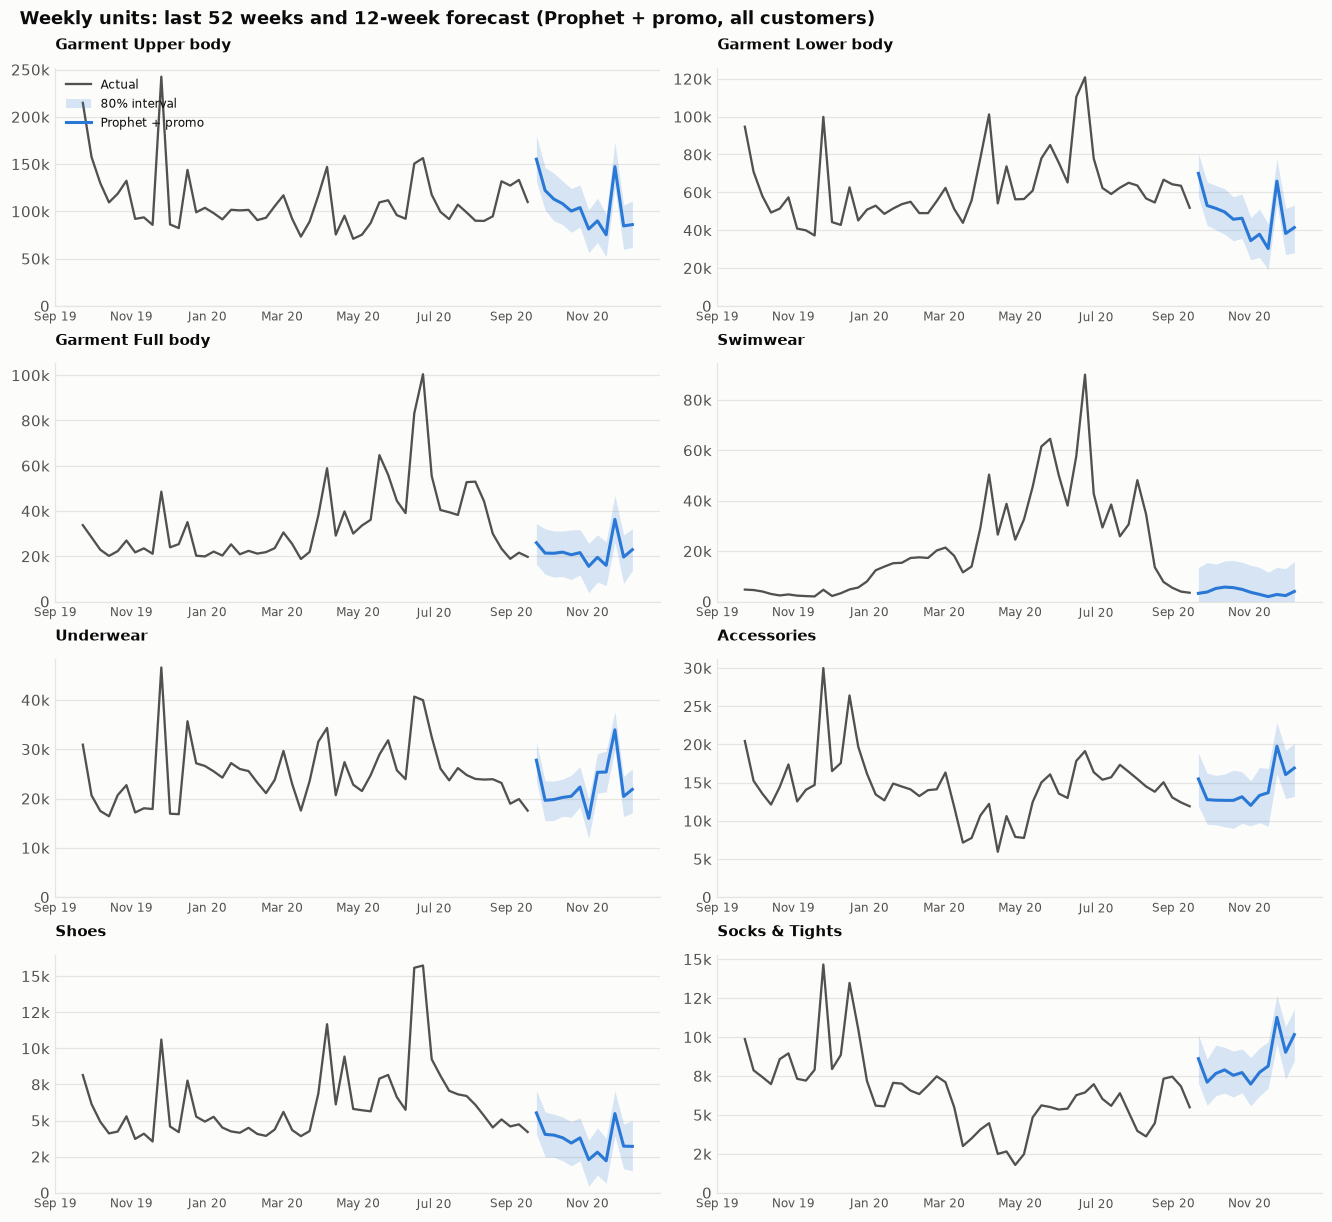

category,Garment Upper body,Garment Lower body,Garment Full body,Swimwear,Underwear,Accessories,Shoes,Socks & Tights
ds,,,,,,,,
2020-09-21,"155,236.000","70,036.000","25,976.000","3,239.000","27,777.000","15,475.000","5,530.000","8,608.000"
2020-09-28,"122,138.000","53,015.000","21,388.000","3,759.000","19,627.000","12,761.000","4,038.000","7,096.000"
2020-10-05,"112,960.000","51,529.000","21,313.000","5,174.000","19,787.000","12,689.000","3,991.000","7,660.000"
2020-10-12,"108,143.000","49,651.000","21,813.000","5,722.000","20,220.000","12,668.000","3,808.000","7,887.000"
2020-10-19,"100,328.000","45,772.000","20,649.000","5,508.000","20,463.000","12,662.000","3,441.000","7,540.000"
2020-10-26,"104,027.000","46,338.000","21,606.000","4,811.000","22,335.000","13,138.000","3,795.000","7,716.000"
2020-11-02,"81,315.000","34,477.000","15,538.000","3,648.000","15,973.000","12,007.000","2,293.000","6,976.000"
2020-11-09,"89,942.000","37,880.000","19,526.000","2,832.000","25,320.000","13,309.000","2,806.000","7,725.000"
2020-11-16,"75,299.000","30,305.000","15,965.000","1,941.000","25,376.000","13,669.000","2,210.000","8,134.000"


In [5]:
fig, axes = plt.subplots(4, 2, figsize=(12, 11), layout="constrained")
for ax, cat in zip(axes.flat, CATS, strict=True):
    hist = series[series.category == cat].tail(HIST)
    f = fc[(fc.category == cat) & (fc.model == BEST)]
    viz.forecast_panel(
        ax,
        (hist.ds, hist.y),
        (f.ds, f.yhat, f.yhat_lower, f.yhat_upper),
        title=cat,
        labels=("Actual", NAMES[BEST], ""),
    )
    viz.thousands_axis(ax, "y")
    ax.tick_params(axis="x", labelsize=8)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
axes.flat[0].legend(loc="upper left", fontsize=8)
fig.suptitle(
    f"Weekly units: last {HIST} weeks and 12-week forecast ({NAMES[BEST]}, {SCOPE})",
    x=0.01,
    ha="left",
    fontweight="semibold",
)
viz.save_fig(fig, f"forecast_forward_{MODE}", FIGURES)
plt.show()

display(fc[fc.model == BEST].pivot(index="ds", columns="category", values="yhat")[CATS].round(0))

## 4. Result

Computed from `forecast_summary_<mode>.json` and the metrics table.

In [6]:
ov = summary["overall"]
beat = summary["categories_where_best_beats_naive_wape"]
a12 = a[a.bucket == whole].set_index("model")
first, last = buckets[0], buckets[-1]
ab = a.set_index(["bucket", "model"])
result = pd.Series(
    {
        "Best Prophet spec (by WAPE)": NAMES[BEST],
        "MAPE, 12-week horizon: best Prophet / seasonal naive": f"{ov[BEST]['mape']:.1%} / {ov['seasonal_naive']['mape']:.1%}",
        "WAPE, 12-week horizon: best Prophet / seasonal naive": f"{ov[BEST]['wape']:.1%} / {ov['seasonal_naive']['wape']:.1%}",
        "Plain Prophet MAPE / WAPE": f"{ov['prophet']['mape']:.1%} / {ov['prophet']['wape']:.1%}",
        f"WAPE weeks {first}: best / naive": f"{ab.loc[(first, BEST), 'wape']:.1%} / {ab.loc[(first, 'seasonal_naive'), 'wape']:.1%}",
        f"WAPE weeks {last}: best / naive": f"{ab.loc[(last, BEST), 'wape']:.1%} / {ab.loc[(last, 'seasonal_naive'), 'wape']:.1%}",
        "Categories where best Prophet beats naive (WAPE)": f"{len(beat)} of {summary['n_categories']}: {', '.join(beat)}",
        "80% interval coverage (best spec)": f"{summary['interval_coverage'][BEST]:.0%}",
    },
    name="value",
)
result.to_frame()

,value
Best Prophet spec (by WAPE),Prophet + promo
"MAPE, 12-week horizon: best Prophet / seasonal naive",23.3% / 30.4%
"WAPE, 12-week horizon: best Prophet / seasonal naive",20.1% / 25.2%
Plain Prophet MAPE / WAPE,22.5% / 20.7%
WAPE weeks 1-4: best / naive,17.9% / 31.6%
WAPE weeks 9-12: best / naive,20.8% / 17.5%
Categories where best Prophet beats naive (WAPE),"4 of 8: Garment Lower body, Garment Upper body..."
80% interval coverage (best spec),60%


**Reading the result.** Prophet beats the seasonal-naive baseline when all categories are pooled, and most clearly in the first weeks of the horizon, but not in every category or at every horizon (see the tables above): repeating last year is a strong baseline for strongly seasonal lines. The prediction intervals cover fewer actuals than their nominal 80%, so they understate uncertainty.

**Caveats.** Less than two years of history per fit (Prophet itself warns that yearly seasonality is then under-identified); the test window includes the 2020 store closures, which no model trained on 2018–19 could anticipate; the promo regressor uses realised promo share in the backtest (a planned-calendar assumption). Hierarchical forecasting (category → article) and a longer history are the natural next steps.